# 15. 파생 변수 5종만으로 같은 실험 — 제공 변수(전류·전압·시간·가압력) 제외
입력(9개): 입열량 V·I·t, 동저항 V/I, 전류/가압력 I/F, 그리고 이 3개 각각의 이동 중앙값 대비 편차(같은 날 직전 20타점)와 직전 타점 대비 변화량.
정의는 1장 보고서 [표 3]의 파생 변수 5종을 따랐다. 나머지는 확정 사양과 같다: 날짜별 개수만으로 학습, 날짜 하나 빼고 평가, 두 데이터에 같은 사양.
학습은 한 번 실행에 약 4.5분만 하고 캐시에 쌓는다(여러 번 실행). 학습이 끝나면 원래 사양(raw: 4개 값 + 파생 3개)과 나란히 비교한다.

In [1]:
import time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.special import expit, logit
from scipy.stats import binomtest
import br
from br import spec as S, budget as B, plot as P
from br.weak import shift_to
from wl.metrics import inclusion_prob, within_loc_auroc
from wl import data as wldata
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
FS = "derived5"
DATA = {"polito": S.load_polito(FS), "kamp": S.load_kamp(FS)}
cache = br.RES / f"same_model_scores_{FS}.pkl"
sc = pd.read_pickle(cache) if cache.exists() else pd.DataFrame(columns=["data", "model", "seed", "row", "score", "prob"])
done = set(map(tuple, sc[["data", "model", "seed"]].drop_duplicates().values))
PLAN = [(m, s) for m in S.MODELS for s in (range(10) if m == "PVC MLP" else range(5) if m != "고정 불량률" else [0])]
t0 = time.time()
for m, s in sorted(PLAN, key=lambda x: (x[1], S.MODELS.index(x[0]))):
    for ds, (X, day, cnt, y, blk) in DATA.items():
        if (ds, m, s) in done or time.time() - t0 > 270:
            continue
        t = time.time()
        score, prob = S.lodo(m, X, day, cnt, s)
        sc = pd.concat([sc, pd.DataFrame({"data": ds, "model": m, "seed": s, "row": np.arange(len(day)), "score": score, "prob": prob})], ignore_index=True)
        sc.to_pickle(cache)
        print(f"{ds:6s} {m:12s} seed={s}  {time.time()-t:5.1f}초", flush=True)
have = sc.groupby(["data", "model"]).seed.nunique()
need = len(PLAN) * 2
n_done = len(set(map(tuple, sc[["data", "model", "seed"]].drop_duplicates().values)))
print(f"진행: {n_done}/{need} 학습 단위 완료")
COMPLETE = n_done == need

kamp   PVC MLP      seed=8   17.4초


polito PVC MLP      seed=9   34.8초


kamp   PVC MLP      seed=9   16.5초


진행: 52/52 학습 단위 완료


## 결과 (학습이 모두 끝난 뒤에만 계산)

In [2]:
RAW = pd.read_pickle(br.RES / "same_model_scores.pkl")
def mean_col(src, ds, model, col, seeds=None):
    g = src[(src.data == ds) & (src.model == model)]
    if seeds is not None: g = g[g.seed.isin(seeds)]
    return np.mean([gg.sort_values("row")[col].values for _, gg in g.groupby("seed")], 0)

if COMPLETE:
    # 1) 일별 개수 MAE (두 입력 세트)
    rows = []
    for nm, src, dd in [("raw(제공4+파생3)", RAW, {"polito": S.load_polito(), "kamp": S.load_kamp()}), ("파생5종", sc, DATA)]:
        for ds, (X, day, cnt, y, blk) in dd.items():
            for m in S.MODELS:
                errs = []
                for s, g in src[(src.data == ds) & (src.model == m) & (src.seed < 5)].groupby("seed"):
                    g = g.sort_values("row"); ok = ~np.isnan(g.prob.values.astype(float))
                    pr = pd.Series(g.prob.values[ok].astype(float)).groupby(day[ok]).sum()
                    errs.append((pr - cnt.loc[pr.index]).abs().mean())
                rows.append({"입력": nm, "데이터": ds, "모델": m, "MAE": np.mean(errs)})
    mae = pd.DataFrame(rows).pivot_table(index=["데이터", "모델"], columns="입력", values="MAE").round(2)
    mae.to_csv(br.RES / "derived5_count_mae.csv", encoding="utf-8-sig"); display(mae)

입력                  raw(제공4+파생3)  파생5종
데이터    모델                             
kamp   AE (정답 미사용)          2.19  2.19
       PVC MLP              2.84  2.15
       고정 불량률               2.19  2.19
       비율맞춤 MLP             2.61  2.64
       집계 로지스틱              1.69  1.78
polito AE (정답 미사용)          2.47  2.47
       PVC MLP              2.60  3.14
       고정 불량률               2.47  2.47
       비율맞춤 MLP             3.10  3.24
       집계 로지스틱              2.72  2.73

In [3]:
if COMPLETE:
    # 2) Stellantis N.V. 검사 예산 — 10시드(PVC) 평균 점수 단일 순위, 대응 비교
    X, day, cnt, y, _ = DATA["polito"]
    body = wldata.load_polito().body.values; loc = wldata.load_polito()["loc"].values
    rng = np.random.default_rng(6); ub = np.unique(body)
    Wb = np.stack([np.bincount(d_, minlength=len(ub)) for d_ in rng.integers(0, len(ub), (5000, len(ub)))])[:, np.searchsorted(ub, body)]
    ud, gi = np.unique(day, return_inverse=True); n = np.bincount(gi); pos = np.bincount(gi, weights=y)
    def ci(a): return f"{np.mean(a):+.3f} [{np.quantile(a,.025):+.3f}, {np.quantile(a,.975):+.3f}]"
    rows = []
    for m in ["PVC MLP", "비율맞춤 MLP", "집계 로지스틱", "AE (정답 미사용)"]:
        a = mean_col(RAW, "polito", m, "score"); d5 = mean_col(sc, "polito", m, "score").astype(float)
        for b in (.05, .1, .2, .3):
            k = np.ceil(b * n - 1e-9); pr = (k / n)[gi]
            pa, pd5 = inclusion_prob(a, k, gi), inclusion_prob(d5, k, gi)
            r_rand = (Wb @ (pr * y)) / (Wb @ y)
            rows.append({"모델": m, "예산": f"{int(b*100)}%", "무작위": round((pr * y).sum() / y.sum(), 3),
                         "raw": round((pa * y).sum() / y.sum(), 3), "파생5종": round((pd5 * y).sum() / y.sum(), 3),
                         "파생5종−무작위 [95%]": ci((Wb @ (pd5 * y)) / (Wb @ y) - r_rand),
                         "파생5종−raw [95%]": ci((Wb @ ((pd5 - pa) * y)) / (Wb @ y))})
    bud = pd.DataFrame(rows); bud.to_csv(br.RES / "derived5_polito_budget.csv", index=False, encoding="utf-8-sig"); display(bud)

,모델,예산,무작위,raw,파생5종,파생5종−무작위 [95%],파생5종−raw [95%]
0,PVC MLP,5%,0.062,0.101,0.038,"-0.025 [-0.053, +0.010]","-0.062 [-0.122, +0.000]"
1,PVC MLP,10%,0.108,0.278,0.063,"-0.046 [-0.086, -0.005]","-0.210 [-0.311, -0.096]"
2,PVC MLP,20%,0.202,0.468,0.114,"-0.090 [-0.150, -0.032]","-0.349 [-0.489, -0.200]"
3,PVC MLP,30%,0.309,0.658,0.127,"-0.184 [-0.248, -0.123]","-0.527 [-0.662, -0.378]"
4,비율맞춤 MLP,5%,0.062,0.203,0.038,"-0.025 [-0.053, +0.010]","-0.159 [-0.253, -0.058]"
5,비율맞춤 MLP,10%,0.108,0.291,0.051,"-0.059 [-0.093, -0.021]","-0.235 [-0.338, -0.107]"
6,비율맞춤 MLP,20%,0.202,0.380,0.101,"-0.102 [-0.144, -0.062]","-0.274 [-0.395, -0.127]"
7,비율맞춤 MLP,30%,0.309,0.456,0.139,"-0.170 [-0.218, -0.120]","-0.309 [-0.459, -0.120]"
8,집계 로지스틱,5%,0.062,0.076,0.063,"-0.001 [-0.048, +0.045]","-0.012 [-0.051, +0.030]"
9,집계 로지스틱,10%,0.108,0.165,0.089,"-0.022 [-0.079, +0.028]","-0.073 [-0.173, +0.013]"


In [4]:
if COMPLETE:
    # 3) 위치 효과 점검 (PVC): 위치 평균 부분 / 위치 안 편차 부분 / 같은 날·위치 안 AUROC
    def loc_parts(s):
        df_ = pd.DataFrame({"s": s, "l": loc, "d": day})
        tot = df_.groupby("l").s.agg(["sum", "count"]); same = df_.groupby(["l", "d"]).s.agg(["sum", "count"])
        a_ = tot.loc[df_.l].values - same.loc[list(zip(df_.l, df_.d))].values
        lm = np.where(a_[:, 1] > 0, a_[:, 0] / np.maximum(a_[:, 1], 1), s.mean())
        return lm, s - lm
    grp = np.char.add(day.astype(str), "_" + loc.astype(str))
    rows = []
    for nm, src in [("raw", RAW), ("파생5종", sc)]:
        s_ = mean_col(src, "polito", "PVC MLP", "score").astype(float); lm, dv = loc_parts(s_)
        k = np.ceil(.1 * n - 1e-9)
        rows.append({"입력": nm, "10% 원래": (inclusion_prob(s_, k, gi) * y).sum() / y.sum(),
                     "10% 위치 평균 부분만": (inclusion_prob(lm, k, gi) * y).sum() / y.sum(),
                     "10% 위치 안 편차만": (inclusion_prob(dv, k, gi) * y).sum() / y.sum(),
                     "같은 날·위치 안 AUROC": within_loc_auroc(y, s_, grp)})
    locchk = pd.DataFrame(rows).round(3); locchk.to_csv(br.RES / "derived5_location_check.csv", index=False, encoding="utf-8-sig"); display(locchk)

,입력,10% 원래,10% 위치 평균 부분만,10% 위치 안 편차만,같은 날·위치 안 AUROC
0,raw,0.278,0.297,0.051,0.576
1,파생5종,0.063,0.057,0.089,0.576


In [5]:
if COMPLETE:
    # 4) KAMP: 1단계 개수(집계 로지스틱) 유의성, 추천 안정성(5시드 평균끼리), 의사라벨 정밀도(Stellantis N.V.)
    Xk, kday, kcnt, _, kblk = DATA["kamp"]
    def day_mae_series(src, ds, m, dd):
        X_, day_, cnt_, y_, b_ = dd[ds]
        p_ = mean_col(src, ds, m, "prob").astype(float); ok = ~np.isnan(p_)
        pr = pd.Series(p_[ok]).groupby(day_[ok]).sum(); return (pr - cnt_.loc[pr.index]).abs()
    e1, e0 = day_mae_series(sc, "kamp", "집계 로지스틱", DATA), day_mae_series(sc, "kamp", "고정 불량률", DATA)
    w_ = int(((e1 - e0) < 0).sum())
    print(f"KAMP 1단계(집계 로지스틱) MAE {e1.mean():.2f} vs 고정 {e0.mean():.2f}, 개선 {w_}/8일, 부호검정 p={binomtest(w_, 8, .5, alternative='greater').pvalue:.3f}")
    def stab(src, ds, dd, frac=.1):
        X_, day_, cnt_, y_, b_ = dd[ds]
        a_, c_ = mean_col(src, ds, "PVC MLP", "score", range(5)).astype(float), mean_col(src, ds, "PVC MLP", "score", range(5, 10)).astype(float)
        ok = ~np.isnan(a_) & ~b_; o = []
        for d in np.unique(day_[ok]):
            m_ = ok & (day_ == d); kk = int(np.ceil(frac * m_.sum())); ix = np.flatnonzero(m_)
            o.append(len(set(ix[np.argsort(-a_[m_])[:kk]]) & set(ix[np.argsort(-c_[m_])[:kk]])) / kk)
        return np.mean(o), np.min(o)
    RAWD = {"polito": S.load_polito(), "kamp": S.load_kamp()}
    print("상위 10% 추천 안정성(5시드 평균끼리, 평균/최저) — KAMP raw:", np.round(stab(RAW, "kamp", RAWD), 3), " 파생5종:", np.round(stab(sc, "kamp", DATA), 3))
    print("                                    — Stellantis N.V. raw:", np.round(stab(RAW, "polito", RAWD), 3), " 파생5종:", np.round(stab(sc, "polito", DATA), 3))
    rows = []
    for nm, src in [("raw", RAW), ("파생5종", sc)]:
        s_ = mean_col(src, "polito", "PVC MLP", "score").astype(float)
        for mult in (1, 5):
            k = np.minimum(mult * cnt.loc[ud].values, n).astype(float); p_ = inclusion_prob(s_, k, gi)
            rows.append({"입력": nm, "의사라벨": f"상위 {mult}×c_d", "표시": int(k.sum()), "실제 불량": round((p_ * y).sum(), 1), "정밀도": round((p_ * y).sum() / k.sum(), 3)})
    display(pd.DataFrame(rows))

KAMP 1단계(집계 로지스틱) MAE 1.78 vs 고정 2.19, 개선 4/8일, 부호검정 p=0.637


상위 10% 추천 안정성(5시드 평균끼리, 평균/최저) — KAMP raw: [0.849 0.524]  파생5종: [0.705 0.1  ]
                                    — Stellantis N.V. raw: [0.925 0.5  ]  파생5종: [0.922 0.667]


,입력,의사라벨,표시,실제 불량,정밀도
0,raw,상위 1×c_d,79,16.0,0.203
1,raw,상위 5×c_d,375,45.0,0.120
2,파생5종,상위 1×c_d,79,7.0,0.089
3,파생5종,상위 5×c_d,375,13.0,0.035


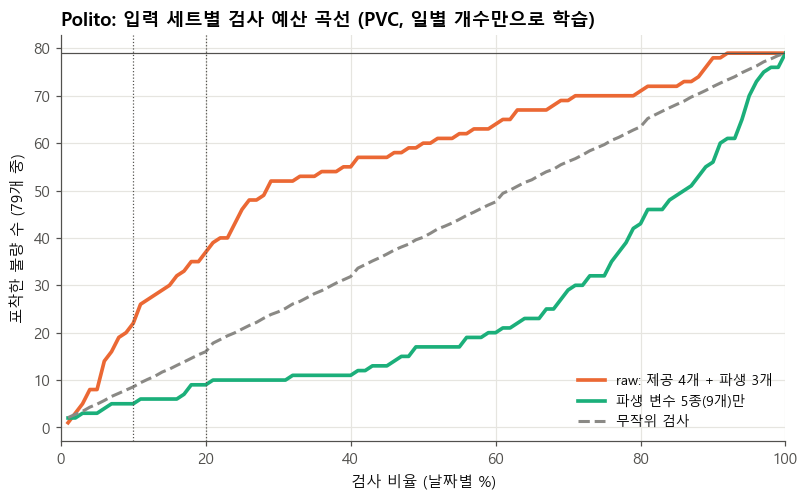

In [6]:
if COMPLETE:
    # 5) 그림: Stellantis N.V. 검사 예산 곡선 raw vs 파생5종 (PVC, 10시드 평균 순위)
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    bb = B.BUDGETS
    rnd = [(np.ceil(b * n - 1e-9) / n * pos).sum() for b in bb]
    for nm, src, col in [("raw: 제공 4개 + 파생 3개", RAW, P.PAL[1]), ("파생 변수 5종(9개)만", sc, P.PAL[2])]:
        s_ = mean_col(src, "polito", "PVC MLP", "score").astype(float)
        ax.plot(bb * 100, [(inclusion_prob(s_, np.ceil(b * n - 1e-9), gi) * y).sum() for b in bb], color=col, lw=2.4, label=nm)
    ax.plot(bb * 100, rnd, "--", color=P.GRAY, label="무작위 검사")
    ax.axhline(y.sum(), color=P.INK2, lw=.8)
    for b in (10, 20): ax.axvline(b, color=P.INK2, lw=.8, ls=":")
    ax.set_xlim(0, 100); ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel("포착한 불량 수 (79개 중)")
    ax.set_title("Stellantis N.V.: 입력 세트별 검사 예산 곡선 (PVC, 일별 개수만으로 학습)", loc="left", fontweight="bold"); ax.legend(loc="lower right", fontsize=9)
    P.save(fig, "13_derived5_vs_raw"); plt.show()